Istallation of libraries

In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Importing the libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Explore data

In [5]:
df = pd.read_csv("Bank_Churn.csv")
print("head:")
print(df.head())
print("tail:")
print(df.tail())


head:
   CustomerId   Surname  CreditScore Geography  Gender  Age  Tenure  \
0    15634602  Hargrave          619    France  Female   42       2   
1    15647311      Hill          608     Spain  Female   41       1   
2    15619304      Onio          502    France  Female   42       8   
3    15701354      Boni          699    France  Female   39       1   
4    15737888  Mitchell          850     Spain  Female   43       2   

     Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0       0.00              1          1               1        101348.88   
1   83807.86              1          0               1        112542.58   
2  159660.80              3          1               0        113931.57   
3       0.00              2          0               0         93826.63   
4  125510.82              1          1               1         79084.10   

   Exited  
0       1  
1       0  
2       1  
3       0  
4       0  
tail:
      CustomerId   Surname  CreditScor

Finding the null value

In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [15]:
print("\nDataset Information:")
print(df.info())



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9972 entries, 0 to 9971
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       9972 non-null   int64  
 1   Surname          9972 non-null   str    
 2   CreditScore      9972 non-null   int64  
 3   Geography        9972 non-null   str    
 4   Gender           9972 non-null   str    
 5   Age              9972 non-null   int64  
 6   Tenure           9972 non-null   int64  
 7   Balance          9972 non-null   float64
 8   NumOfProducts    9972 non-null   int64  
 9   HasCrCard        9972 non-null   int64  
 10  IsActiveMember   9972 non-null   int64  
 11  EstimatedSalary  9972 non-null   float64
 12  Exited           9972 non-null   int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1012.9 KB
None


In [17]:
df.dropna()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9967,15603794,Pugliesi,623,France,Male,48,5,118469.38,1,1,1,158590.25,0
9968,15733491,McGregor,512,Germany,Female,40,8,153537.57,2,0,0,23101.13,0
9969,15806360,Hou,609,France,Male,41,6,0.00,1,0,1,112585.19,0
9970,15587133,Thompson,518,France,Male,42,7,151027.05,2,1,0,119377.36,0


Basic visualization

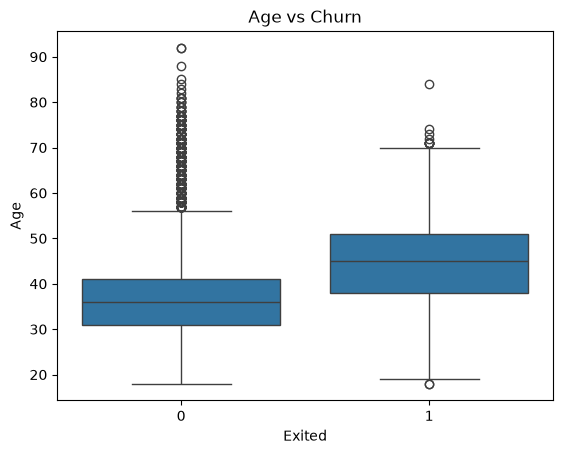

In [ ]:
sns.boxplot(x="Exited", y="Age", data=df)
plt.title("Age vs Churn")
plt.xlabel("Exited")
plt.ylabel("Age")
plt.show()#bi variate

Correlation heat map

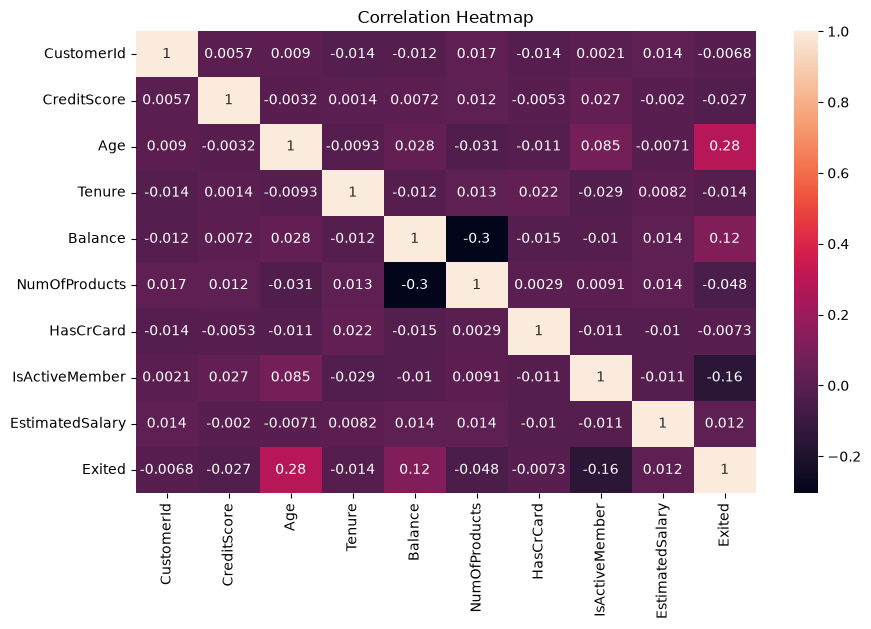

In [14]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)
plt.title("Correlation Heatmap")
plt.show()

Feature Engineering

In [19]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 30, 50, 100],
    labels=["Young", "Middle", "Senior"]
)
print(df[["Age", "AgeGroup"]].head(20))

    Age AgeGroup
0    42   Middle
1    41   Middle
2    42   Middle
3    39   Middle
4    43   Middle
5    44   Middle
6    50   Middle
7    29    Young
8    44   Middle
9    27    Young
10   31   Middle
11   24    Young
12   34   Middle
13   25    Young
14   35   Middle
15   45   Middle
16   58   Senior
17   24    Young
18   45   Middle
19   24    Young


Label encoder

In [23]:
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
print(df["Gender"].head(20))

0     0
1     0
2     0
3     0
4     0
5     1
6     1
7     0
8     1
9     1
10    1
11    1
12    0
13    0
14    0
15    1
16    1
17    0
18    1
19    0
Name: Gender, dtype: int64


In [61]:
print(df["Gender"].unique())

[0 1]


Class Imbalance

Exited
0    7941
1    2031
Name: count, dtype: int64
Exited
0    79.632972
1    20.367028
Name: proportion, dtype: float64


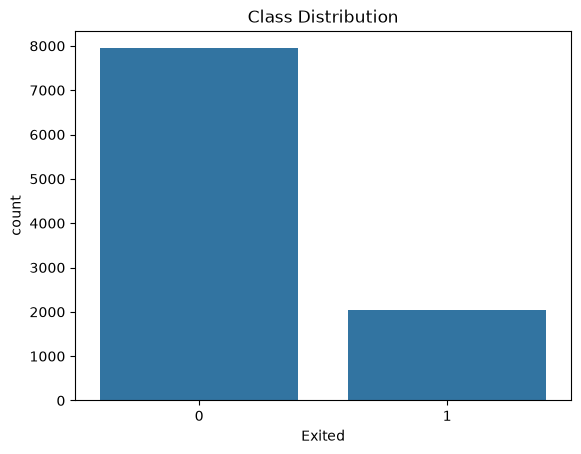

In [24]:
print(df["Exited"].value_counts())
print(df["Exited"].value_counts(normalize=True) * 100)
sns.countplot(x="Exited", data=df)
plt.title("Class Distribution")
plt.show()

Outliers checking

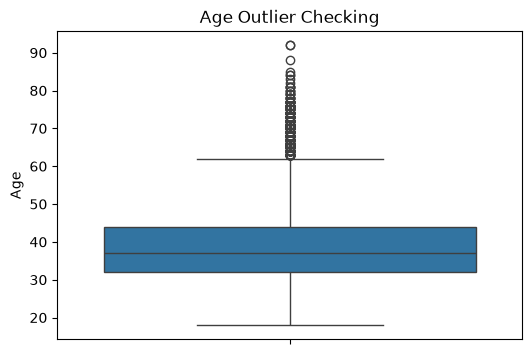

In [41]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df["Age"])
plt.title("Age Outlier Checking")
plt.show()

Split into X&Y

In [48]:
X=df.drop("Exited", axis=1)
y=df["Exited"]
print(df.head(20))

    CustomerId    Surname  CreditScore Geography  Gender  Age  Tenure  \
0     15634602   Hargrave          619    France       0   42       2   
1     15647311       Hill          608     Spain       0   41       1   
2     15619304       Onio          502    France       0   42       8   
3     15701354       Boni          699    France       0   39       1   
4     15737888   Mitchell          850     Spain       0   43       2   
5     15574012        Chu          645     Spain       1   44       8   
6     15592531   Bartlett          822    France       1   50       7   
7     15656148     Obinna          376   Germany       0   29       4   
8     15792365         He          501    France       1   44       4   
9     15592389         H?          684    France       1   27       2   
10    15767821     Bearce          528    France       1   31       6   
11    15737173    Andrews          497     Spain       1   24       3   
12    15632264        Kay          476    France   

In [60]:
print(X.columns.tolist())

['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


Train_test_split

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print(X.head(20))


    CustomerId    Surname  CreditScore Geography  Gender  Age  Tenure  \
0     15634602   Hargrave          619    France       0   42       2   
1     15647311       Hill          608     Spain       0   41       1   
2     15619304       Onio          502    France       0   42       8   
3     15701354       Boni          699    France       0   39       1   
4     15737888   Mitchell          850     Spain       0   43       2   
5     15574012        Chu          645     Spain       1   44       8   
6     15592531   Bartlett          822    France       1   50       7   
7     15656148     Obinna          376   Germany       0   29       4   
8     15792365         He          501    France       1   44       4   
9     15592389         H?          684    France       1   27       2   
10    15767821     Bearce          528    France       1   31       6   
11    15737173    Andrews          497     Spain       1   24       3   
12    15632264        Kay          476    France   

In [ ]:

X = df.drop(["Exited", "CustomerId", "Surname", "Geography", "AgeGroup"], axis=1)
y = df["Exited"]

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Model testing

In [53]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [55]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


c:\Users\surya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Model Evaluation

In [56]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7964912280701755


   calssification report

In [57]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.98      0.88      1589
           1       0.50      0.08      0.14       406

    accuracy                           0.80      1995
   macro avg       0.65      0.53      0.51      1995
weighted avg       0.74      0.80      0.73      1995



In [59]:
import joblib
joblib.dump(model, "bank_churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [6]:
print(df)

      CustomerId   Surname  CreditScore Geography  Gender  Age  Tenure  \
0       15634602  Hargrave          619    France  Female   42       2   
1       15647311      Hill          608     Spain  Female   41       1   
2       15619304      Onio          502    France  Female   42       8   
3       15701354      Boni          699    France  Female   39       1   
4       15737888  Mitchell          850     Spain  Female   43       2   
...          ...       ...          ...       ...     ...  ...     ...   
9967    15603794  Pugliesi          623    France    Male   48       5   
9968    15733491  McGregor          512   Germany  Female   40       8   
9969    15806360       Hou          609    France    Male   41       6   
9970    15587133  Thompson          518    France    Male   42       7   
9971    15721377      Chou          833    France  Female   34       3   

        Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0          0.00              1   